# Лабораторная работа №2. Классификация

**Survived**:
* 0 — пассажир погиб;
* 1 — пассажир выжил.

Сначала загрузим данные:


In [1]:
from pathlib import Path
import pandas as pd

data_dir = Path('/Users/xololibra/Desktop/ml_course_mai/classification/data')
df = pd.read_csv(data_dir / 'train.csv')

display(df.head())
print('Размер датасета:', df.shape)
df.info()


,Id,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Survived
0,87482818,3,male,22.0,1,0,7.2500,S,0
1,52187593,1,female,38.0,1,0,71.2833,C,1
2,24292843,3,female,26.0,0,0,7.9250,S,1
3,23247479,1,male,54.0,0,0,51.8625,S,0
4,83808344,3,male,2.0,3,1,21.0750,S,0


Размер датасета: (891, 9)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Id        891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    str    
 3   Age       714 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Embarked  889 non-null    str    
 8   Survived  891 non-null    int64  
dtypes: float64(2), int64(5), str(2)
memory usage: 62.8 KB


Входные признаки имеют следующий смысл:

| Признак | Значение |
|---|---|
| Pclass | Класс билета: 1, 2 или 3 |
| Sex | Пол пассажира |
| Age | Возраст |
| SibSp | Число братьев, сестёр и супругов на борту |
| Parch | Число родителей и детей на борту |
| Fare | Стоимость проезда |
| Embarked | Порт посадки |

`Id` исключаем: произвольный идентификатор не описывает пассажира и может провоцировать запоминание. `Survived` также исключаю из входа — это целевая переменная.

Проверим пропуски, повторы и распределение ответов:


In [2]:
feature_columns = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']

print('Пропуски:')
print(df.isna().sum())
print('Полные повторы строк:', df.duplicated().sum())
print('Повторы признаков:', df.duplicated(feature_columns).sum())

display(pd.DataFrame({
    'Количество': df['Survived'].value_counts(),
    'Доля': df['Survived'].value_counts(normalize=True),
}).sort_index().round(4))


Пропуски:
Id            0
Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Embarked      2
Survived      0
dtype: int64
Полные повторы строк: 0
Повторы признаков: 127


,Количество,Доля
Survived,,
0,549,0.6162
1,342,0.3838


Есть 891 размеченная строка. В `Age` пропущено 177 значений, в `Embarked` — 2; остальные колонки заполнены. Погибших 549, выживших 342: доля положительного класса около 38.4%.

Полных повторов строк нет, но у 127 строк повторяется набор из семи характеристик. Это не доказывает, что перед нами один и тот же пассажир: несколько людей могут иметь одинаковые возраст, пол, класс и другие признаки. Поэтому автоматически удалять такие строки опсано. Тем более одинаковым признакам иногда соответствуют разные ответы.

Уже видно, что постоянный прогноз «все погибли» даст около 61.6% Accuracy на всём размеченном наборе, но не обнаружит ни одного выжившего.


# Обучающая и валидационная выборки

Выделим 20% размеченных строк для валидации. `stratify=y` сохраняет приблизительное соотношение классов, `random_state` фиксирует разбиение.


In [3]:
from sklearn.model_selection import train_test_split

X = df[feature_columns]
y = df['Survived']

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42,
)

print('Обучение:', X_train.shape, '| Валидация:', X_val.shape)
display(pd.DataFrame({
    'Train: доля': y_train.value_counts(normalize=True),
    'Validation: доля': y_val.value_counts(normalize=True),
}).sort_index().round(4))

train_data = X_train.assign(Survived=y_train)


Обучение: (712, 7) | Валидация: (179, 7)


,Train: доля,Validation: доля
Survived,,
0,0.6166,0.6145
1,0.3834,0.3855


Получилось 712 обучающих и 179 валидационных строк. Доля выживших в обеих частях близка к исходной. Совпадающие характеристики могут принадлежать разным людям; их наличие ограничивает интерпретацию оценки как проверки на полностью новых профилях пассажиров.


# Первичный анализ обучающей части

Дальнейшие зависимости признаков от ответа исследую только на train. Посмотрим на долю выживших для категорий.

,count,survival_rate
Sex,,
female,255,0.729
male,457,0.190


,count,survival_rate
Pclass,,
1,184,0.620
2,141,0.489
3,387,0.233


,count,survival_rate
Embarked,,
C,134,0.560
Q,62,0.387
S,514,0.335
NaN,2,1.000


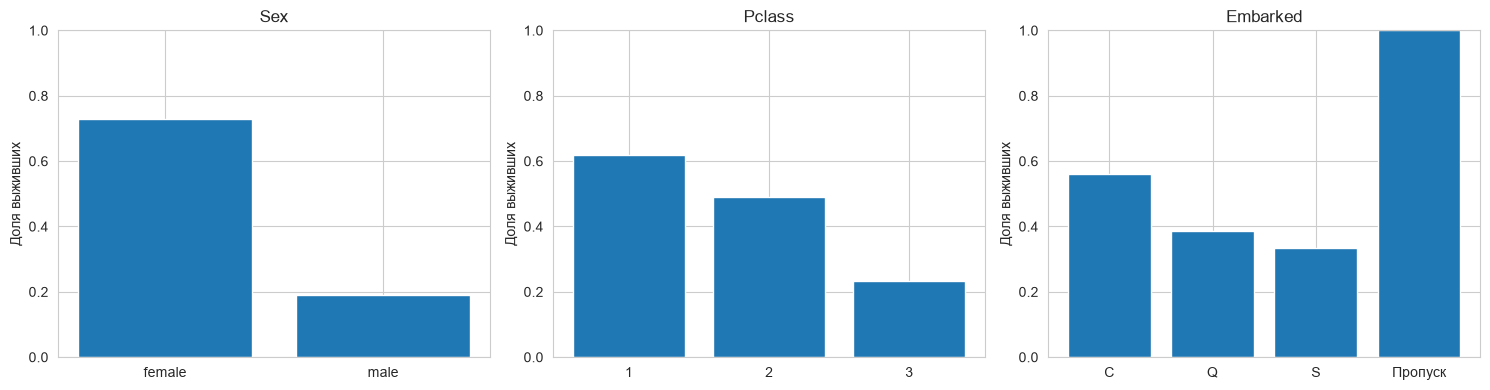

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, feature in zip(axes, ['Sex', 'Pclass', 'Embarked']):
    stats = train_data.groupby(feature, dropna=False).agg(
        count=('Survived', 'size'),
        survival_rate=('Survived', 'mean'),
    )
    display(stats.round(3))
    labels = [str(value) if pd.notna(value) else 'Пропуск' for value in stats.index]
    ax.bar(labels, stats['survival_rate'])
    ax.set(title=feature, ylabel='Доля выживших', ylim=(0, 1))

plt.tight_layout()
plt.show()


В обучающей части доля выживших среди женщин составляет 72.9%, среди мужчин — 19.0%. Для первого класса она равна 62.0%, для третьего — 23.3%. Поэтому пол и класс билета выглядят полезными для предсказания. Порт посадки тоже связан с распределением ответов, но группы различаются по размеру и составу. Наблюдаемая связь не устанавливает причинность.


Теперь посмотрим на возраст и стоимость проезда. Пропуски возраста на гистограмме не представлены, поэтому отдельно сравним строки с известным и неизвестным возрастом.


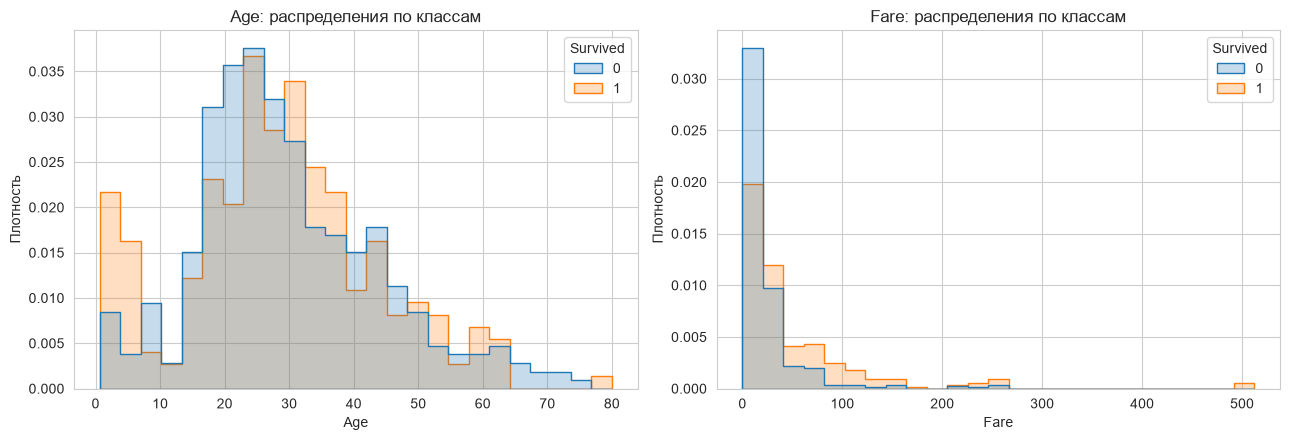

Медианы по классам:


,Age,Fare,SibSp,Parch
Survived,,,,
0,28.0,10.50,0.0,0.0
1,28.5,26.25,0.0,0.0


,count,survival_rate
Age_missing,,
False,567,0.409
True,145,0.283


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, feature in zip(axes, ['Age', 'Fare']):
    sns.histplot(
        data=train_data, x=feature, hue='Survived',
        bins=25, element='step', stat='density', common_norm=False, ax=ax,
    )
    ax.set(title=f'{feature}: распределения по классам',
           xlabel=feature, ylabel='Плотность')

plt.tight_layout()
plt.show()

numeric_summary = train_data.groupby('Survived')[['Age', 'Fare', 'SibSp', 'Parch']].median()
print('Медианы по классам:')
display(numeric_summary.round(2))
age_missing_stats = train_data.assign(Age_missing=train_data['Age'].isna()).groupby(
    'Age_missing',
).agg(count=('Survived', 'size'), survival_rate=('Survived', 'mean'))
display(age_missing_stats.round(3))


Медианная стоимость проезда у выживших в train — 26.25, у погибших — 10.50. Медианный возраст — 28.5 и 28.0 соответственно. Возраст или цена билета по отдельности не дают однозначного ответа. Пропуск возраста также встречается у обоих классов; его нельзя интерпретировать как признак конкретного исхода.


# Подготовка признаков

Для числовых признаков `Age`, `SibSp`, `Parch`, `Fare` заполню пропуски медианой. Она менее чувствительна к крайним значениям, чем среднее. Для категорий `Pclass`, `Sex`, `Embarked` использую наиболее частое значение.

Создам два преобразования:
* для дерева, леса и бустинга — заполнение пропусков и кодирование;
* для SVM и KNN — то же самое плюс `StandardScaler` для числовых колонок.

У KNN прогноз зависит от расстояний: без масштабирования стоимость проезда может численно подавлять другие признаки. SVM также зависит от геометрии пространства. Деревьям масштабирование обычно не нужно: они сравнивают значения признака с порогами.



In [6]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = ['Age', 'SibSp', 'Parch', 'Fare']
categorical_features = ['Pclass', 'Sex', 'Embarked']


def make_preprocessor(scale_numeric=False):
    numeric_steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale_numeric:
        numeric_steps.append(('scaler', StandardScaler()))

    return ColumnTransformer([
        ('num', Pipeline(numeric_steps), numeric_features),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), categorical_features),
    ])


preprocess_tree = make_preprocessor()
preprocess_scaled = make_preprocessor(scale_numeric=True)


# Метрики и baseline

Для положительного класса `Survived = 1`:

* **TP** — правильно предсказали выживание;
* **TN** — правильно предсказали гибель;
* **FP** — предсказали выживание, но пассажир погиб;
* **FN** — предсказали гибель, но пассажир выжил.

$$Accuracy = \frac{TP+TN}{TP+TN+FP+FN},\qquad Precision = \frac{TP}{TP+FP}$$
$$Recall = \frac{TP}{TP+FN},\qquad F_1 = \frac{2TP}{2TP+FP+FN}$$

Precision характеризует правильность положительных прогнозов, Recall — долю обнаруженных выживших. F1 объединяет их гармоническим средним и не учитывает TN напрямую.

В матрице ошибок ниже строки всегда обозначают настоящий класс, столбцы — прогноз; порядок классов `[0, 1]`, то есть `[[TN, FP], [FN, TP]]`.

Сначала узнаем, какое качество даст самое простое правило: всем предсказывать наиболее частый в train класс.


In [7]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
)


def classification_metrics(y_true, prediction):
    return {
        'Accuracy': accuracy_score(y_true, prediction),
        'Precision': precision_score(y_true, prediction, zero_division=0),
        'Recall': recall_score(y_true, prediction, zero_division=0),
        'F1': f1_score(y_true, prediction, pos_label=1, zero_division=0),
    }


baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)
baseline_prediction = baseline.predict(X_val)
baseline_metrics = classification_metrics(y_val, baseline_prediction)

display(pd.DataFrame([baseline_metrics], index=['Dummy baseline']).round(4))
print(confusion_matrix(y_val, baseline_prediction, labels=[0, 1]))


,Accuracy,Precision,Recall,F1
Dummy baseline,0.6145,0.0,0.0,0.0


[[110   0]
 [ 69   0]]


Baseline получил Accuracy = 0.6145, но Precision, Recall и F1 равны нулю. Он предсказал гибель всем 179 пассажирам валидации и пропустил всех 69 выживших. Поэтому Accuracy без анализа положительного класса создаёт слишком благоприятное впечатление.


# Обучение и выбор настроек

В первой лабораторной я проверял несколько значений `alpha` у Ridge и выбирал то, которое давало меньшую ошибку на валидации. Здесь поступлю так же: обучу несколько вариантов каждой модели и выберу вариант с наибольшим Validation F1.

Все варианты обучаю на `X_train`, а сравниваю на уже выделенной `X_val`. Дополнительно считаю Train F1: если модель хорошо отвечает на обучающих примерах и значительно хуже на валидационных, это может указывать на переобучение.

Пока буду переводить вероятность в класс с порогом 0.5. После выбора настроек отдельно проверю, можно ли улучшить F1 изменением порога.

В циклах `product` перебирает все сочетания указанных настроек. Выражение `predict_proba(...)[:, 1]` берёт вероятность класса 1, а сравнение с 0.5 переводит её в метку. При равных F1 оставляю первый проверенный вариант.


# Дерево решений

Дерево задаёт последовательность вопросов о признаках. В каждом узле выбирается разбиение, уменьшающее неоднородность классов. Сравним два критерия:

$$Gini = 1 - \sum_k p_k^2, \qquad Entropy = -\sum_k p_k\log_2 p_k$$

Здесь $p_k$ — доля класса $k$ в узле; для нулевой доли вклад в энтропию принимается равным нулю. В чистом узле все объекты одного класса, поэтому оба критерия равны нулю.

Для каждого критерия проверим одинаковые ограничения сложности: глубины 3, 5, 8 и без ограничения (`None`), минимум 1, 3 или 8 объектов в листе. Получится 12 вариантов на критерий. Все 24 дерева обучаются на одних строках и оцениваются на той же валидации при пороге 0.5.

Сохраним варианты в словарь и сравним результаты в таблице. Затем отдельно покажем лучший вариант Gini и лучший вариант энтропии. Выбирать будем по валидационному F1: численные значения самих критериев имеют разные шкалы. При равенстве F1 оставляю первый проверенный вариант, как и у остальных моделей.


In [8]:
from itertools import product
from sklearn.tree import DecisionTreeClassifier, plot_tree

models = {}
tree_candidates = {}
rows = []

for criterion, depth, leaf in product(['gini', 'entropy'], [3, 5, 8, None], [1, 3, 8]):
    name = f'{criterion}, depth={depth}, leaf={leaf}'
    model = Pipeline([
        ('preprocess', clone(preprocess_tree)),
        ('classifier', DecisionTreeClassifier(
            criterion=criterion, max_depth=depth, min_samples_leaf=leaf, random_state=42,
        )),
    ])
    model.fit(X_train, y_train)
    tree_candidates[name] = model

    pred_train = (model.predict_proba(X_train)[:, 1] >= 0.5).astype(int)
    pred_val = (model.predict_proba(X_val)[:, 1] >= 0.5).astype(int)
    rows.append({
        'model': name,
        'criterion': criterion,
        'Train F1': f1_score(y_train, pred_train),
        'Validation F1': f1_score(y_val, pred_val),
        'Precision': precision_score(y_val, pred_val, zero_division=0),
        'Recall': recall_score(y_val, pred_val, zero_division=0),
    })

tree_results = pd.DataFrame(rows).set_index('model').sort_values(
    'Validation F1', ascending=False, kind='stable',
)
display(tree_results.round(4))

criterion_comparison = tree_results.groupby('criterion', sort=False).head(1)
print('Лучший вариант каждого критерия при пороге 0.5:')
display(criterion_comparison.round(4))

best_tree_name = tree_results['Validation F1'].idxmax()
tree_model = tree_candidates[best_tree_name]
models['Decision Tree'] = tree_model
print('Выбрано дерево:', best_tree_name)


,criterion,Train F1,Validation F1,Precision,Recall
model,,,,,
"entropy, depth=None, leaf=8",entropy,0.8154,0.7910,0.8154,0.7681
"entropy, depth=3, leaf=1",entropy,0.7413,0.7903,0.8909,0.7101
"entropy, depth=3, leaf=3",entropy,0.7413,0.7903,0.8909,0.7101
"entropy, depth=3, leaf=8",entropy,0.7413,0.7903,0.8909,0.7101
"gini, depth=3, leaf=1",gini,0.7405,0.7874,0.8621,0.7246
"gini, depth=3, leaf=3",gini,0.7405,0.7874,0.8621,0.7246
"gini, depth=3, leaf=8",gini,0.7405,0.7874,0.8621,0.7246
"gini, depth=8, leaf=1",gini,0.8658,0.7846,0.8361,0.7391
"gini, depth=8, leaf=3",gini,0.8373,0.7786,0.8226,0.7391


Лучший вариант каждого критерия при пороге 0.5:


,criterion,Train F1,Validation F1,Precision,Recall
model,,,,,
"entropy, depth=None, leaf=8",entropy,0.8154,0.7910,0.8154,0.7681
"gini, depth=3, leaf=1",gini,0.7405,0.7874,0.8621,0.7246


Выбрано дерево: entropy, depth=None, leaf=8


Лучший вариант Gini получил Validation F1 = 0.7874 (max_depth=3, min_samples_leaf=1). У энтропии лучший Validation F1 = 0.7910 (max_depth=None, min_samples_leaf=8). Разница составляет 0.0036 в пользу энтропии. По установленному правилу выбираю **criterion="entropy"**, без ограничения глубины, но с минимумом 8 объектов в листе. Это небольшой перевес на одном разбиении, а не доказательство универсального превосходства энтропии.

У выбранного дерева при пороге 0.5: Train F1 = 0.8154, Validation F1 = 0.7910, Precision = 0.8154, Recall = 0.7681. Разрыв Train F1 − Validation F1 равен 0.0243; качество на валидации немного ниже обучающего. Для сравнения, дерево с энтропией без ограничения глубины и с одним объектом в листе получило Train F1 = 0.9764 и Validation F1 = 0.7407. У него разрыв заметно больше: это признак переобучения. Ограничение размера листа помогло обобщению.

В дальнейшем для дерева использую выбранную энтропию. После отдельного подбора порога 0.40 его валидационный F1 составляет 0.7971.


Покажем первые уровни выбранного дерева. Цвет и распределение классов помогают понять, какие правила оно использует. `max_depth=2` здесь ограничивает только рисунок, а не обученную модель.


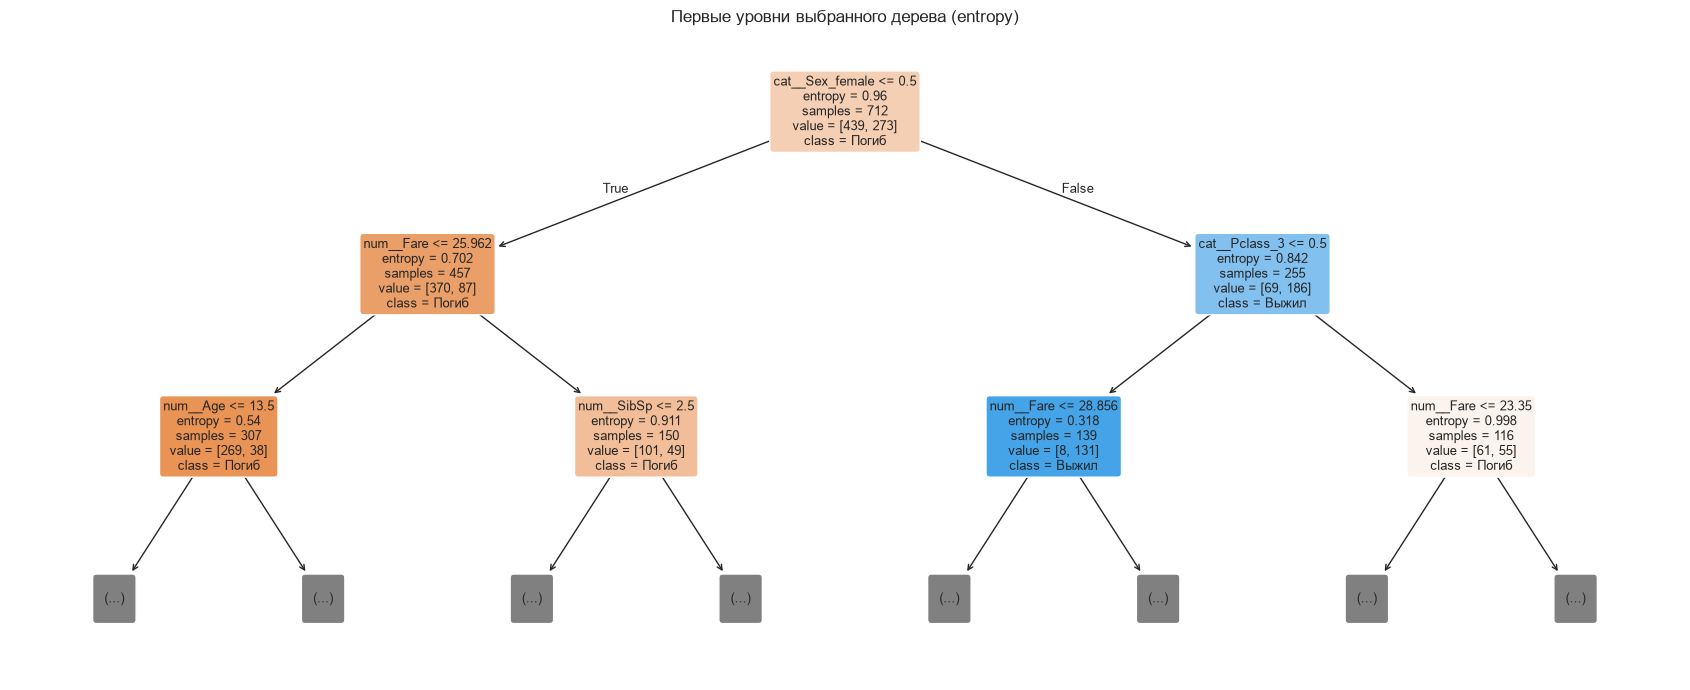

In [9]:
tree_pipeline = models['Decision Tree']
tree_classifier = tree_pipeline.named_steps['classifier']
tree_feature_names = tree_pipeline.named_steps['preprocess'].get_feature_names_out()

fig, ax = plt.subplots(figsize=(17, 7))
plot_tree(
    tree_classifier,
    feature_names=tree_feature_names,
    class_names=['Погиб', 'Выжил'],
    max_depth=2,
    filled=True,
    rounded=True,
    impurity=True,
    fontsize=9,
    ax=ax,
)
ax.set_title(f'Первые уровни выбранного дерева ({tree_classifier.criterion})')
plt.tight_layout()
plt.show()


# Случайный лес

Попробуем случайный лес. Он объединяет деревья, обученные на bootstrap-выборках: строки выбираются случайно с возвращением. При каждом разбиении рассматривается случайное подмножество признаков. В классификации лес усредняет вероятности отдельных деревьев.

Как и в первой ЛР, возьмём 300 деревьев. На той же валидации проверим глубины 5, 8 и без ограничения, а также минимум 2 или 5 объектов в листе. Масштабирование для леса не требуется.


In [10]:
from sklearn.ensemble import RandomForestClassifier

forest_candidates = {}
rows = []

for depth, leaf in product([5, 8, None], [2, 5]):
    name = f'depth={depth}, leaf={leaf}'
    model = Pipeline([
        ('preprocess', clone(preprocess_tree)),
        ('classifier', RandomForestClassifier(
            n_estimators=300, max_depth=depth, min_samples_leaf=leaf,
            max_features='sqrt', random_state=42, n_jobs=1,
        )),
    ])
    model.fit(X_train, y_train)
    forest_candidates[name] = model

    pred_train = (model.predict_proba(X_train)[:, 1] >= 0.5).astype(int)
    pred_val = (model.predict_proba(X_val)[:, 1] >= 0.5).astype(int)
    rows.append({
        'model': name,
        'Train F1': f1_score(y_train, pred_train),
        'Validation F1': f1_score(y_val, pred_val),
        'Precision': precision_score(y_val, pred_val, zero_division=0),
        'Recall': recall_score(y_val, pred_val, zero_division=0),
    })

forest_results = pd.DataFrame(rows).set_index('model').sort_values(
    'Validation F1', ascending=False, kind='stable',
)
display(forest_results.round(4))

best_forest_name = forest_results['Validation F1'].idxmax()
forest_model = forest_candidates[best_forest_name]
models['Random Forest'] = forest_model
print('Выбран лес:', best_forest_name)


,Train F1,Validation F1,Precision,Recall
model,,,,
"depth=None, leaf=2",0.8709,0.8160,0.9107,0.7391
"depth=8, leaf=2",0.8452,0.8065,0.9091,0.7246
"depth=5, leaf=5",0.7607,0.7692,0.9375,0.6522
"depth=8, leaf=5",0.7992,0.7586,0.9362,0.6377
"depth=None, leaf=5",0.7992,0.7586,0.9362,0.6377
"depth=5, leaf=2",0.7734,0.7434,0.9545,0.6087


Выбран лес: depth=None, leaf=2


На валидации выбран лес без ограничения глубины и с min_samples_leaf=2. При пороге 0.5: Train F1 = 0.8709, Validation F1 = 0.8160, Precision = 0.9107, Recall = 0.7391. Разница с выбранным деревом на энтропии по Validation F1 составляет +0.0250. Усреднение разнообразных деревьев может улучшать обобщение, но лес тоже способен переобучаться: это оцениваем по разрыву train и validation.


# Градиентный бустинг

Теперь обучим градиентный бустинг. В отличие от леса, здесь деревья добавляются последовательно: каждое следующее приближает направление уменьшения функции потерь текущего ансамбля. В классификации это антиградиент потерь, а не просто разность метки и предсказанного класса.

Проверим 100 и 200 деревьев, скорости обучения 0.05 и 0.1, глубины 2 и 3. При меньшем `learning_rate` вклад одного дерева слабее, поэтому может понадобиться больше деревьев. Выберем сочетание с лучшим F1 на той же валидации.


In [11]:
from sklearn.ensemble import GradientBoostingClassifier

boosting_candidates = {}
rows = []

for count, rate, depth in product([100, 200], [0.05, 0.1], [2, 3]):
    name = f'trees={count}, rate={rate}, depth={depth}'
    model = Pipeline([
        ('preprocess', clone(preprocess_tree)),
        ('classifier', GradientBoostingClassifier(
            n_estimators=count, learning_rate=rate, max_depth=depth,
            min_samples_leaf=5, random_state=42,
        )),
    ])
    model.fit(X_train, y_train)
    boosting_candidates[name] = model

    pred_train = (model.predict_proba(X_train)[:, 1] >= 0.5).astype(int)
    pred_val = (model.predict_proba(X_val)[:, 1] >= 0.5).astype(int)
    rows.append({
        'model': name,
        'Train F1': f1_score(y_train, pred_train),
        'Validation F1': f1_score(y_val, pred_val),
        'Precision': precision_score(y_val, pred_val, zero_division=0),
        'Recall': recall_score(y_val, pred_val, zero_division=0),
    })

boosting_results = pd.DataFrame(rows).set_index('model').sort_values(
    'Validation F1', ascending=False, kind='stable',
)
display(boosting_results.round(4))

best_boosting_name = boosting_results['Validation F1'].idxmax()
boosting_model = boosting_candidates[best_boosting_name]
models['Gradient Boosting'] = boosting_model
print('Выбран бустинг:', best_boosting_name)


,Train F1,Validation F1,Precision,Recall
model,,,,
"trees=200, rate=0.1, depth=2",0.8421,0.8160,0.9107,0.7391
"trees=200, rate=0.05, depth=2",0.7851,0.8067,0.9600,0.6957
"trees=100, rate=0.1, depth=2",0.7792,0.8034,0.9792,0.6812
"trees=200, rate=0.05, depth=3",0.8594,0.7934,0.9231,0.6957
"trees=200, rate=0.1, depth=3",0.9025,0.7903,0.8909,0.7101
"trees=100, rate=0.05, depth=3",0.7894,0.7899,0.9400,0.6812
"trees=100, rate=0.1, depth=3",0.8527,0.7869,0.9057,0.6957
"trees=100, rate=0.05, depth=2",0.7463,0.7826,0.9783,0.6522


Выбран бустинг: trees=200, rate=0.1, depth=2


На валидации выбран бустинг из 200 деревьев глубины 2 со скоростью обучения 0.1. Для выбранной конфигурации при пороге 0.5: Train F1 = 0.8421, Validation F1 = 0.8160, Precision = 0.9107, Recall = 0.7391. Разница с лесом на том же разбиении: +0.0000 по F1. Это результат конкретных данных и проверенных настроек, а не универсальное превосходство одного ансамбля над другим.


# Метод опорных векторов

Попробуем SVM с ядром RBF. Линейный SVM ищет границу с широким зазором между классами, а ядро RBF позволяет строить нелинейную границу. Параметр `C` определяет штраф за нарушения зазора, `gamma` — насколько локально действует отдельный объект. Для этого алгоритма используем масштабирование числовых признаков.

SVC выдаёт score, который сам по себе не является вероятностью. Чтобы дальше выбирать порог вероятности так же, как у остальных моделей, добавлю `CalibratedClassifierCV` с сигмоидальной калибровкой. Он учится переводить score в вероятность выживания.

Для калибровки обучающая часть внутренне разбивается на пять частей: оценки для каждой части получают от модели, обученной на остальных четырёх. По этим оценкам и ответам обучается преобразование в вероятность. Затем базовый pipeline обучается на всей обучающей части (`ensemble=False`). Препроцессинг расположен внутри этого pipeline и заново обучается на каждом внутреннем разбиении.

Эти внутренние разбиения нужны для калибровки. Настройки `C` и `gamma` по-прежнему выбираю по F1 на нашей отдельной `X_val`; в обучении и калибровке она не участвует. Проверим `C` от 0.3 до 10 и два варианта `gamma`.


In [12]:
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import StratifiedKFold

svm_candidates = {}
rows = []

for C, gamma in product([0.3, 1, 3, 10], ['scale', 0.1]):
    name = f'C={C}, gamma={gamma}'
    svm_pipeline = Pipeline([
        ('preprocess', clone(preprocess_scaled)),
        ('svm', SVC(kernel='rbf', C=C, gamma=gamma, random_state=42)),
    ])
    model = CalibratedClassifierCV(
        estimator=svm_pipeline,
        method='sigmoid',
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
        ensemble=False,
    )
    model.fit(X_train, y_train)
    svm_candidates[name] = model

    pred_train = (model.predict_proba(X_train)[:, 1] >= 0.5).astype(int)
    pred_val = (model.predict_proba(X_val)[:, 1] >= 0.5).astype(int)
    rows.append({
        'model': name,
        'Train F1': f1_score(y_train, pred_train),
        'Validation F1': f1_score(y_val, pred_val),
        'Precision': precision_score(y_val, pred_val, zero_division=0),
        'Recall': recall_score(y_val, pred_val, zero_division=0),
    })

svm_results = pd.DataFrame(rows).set_index('model').sort_values(
    'Validation F1', ascending=False, kind='stable',
)
display(svm_results.round(4))

best_svm_name = svm_results['Validation F1'].idxmax()
svm_model = svm_candidates[best_svm_name]
models['SVM'] = svm_model
print('Выбран SVM:', best_svm_name)


,Train F1,Validation F1,Precision,Recall
model,,,,
"C=1, gamma=scale",0.7628,0.8197,0.9434,0.7246
"C=0.3, gamma=scale",0.7548,0.8160,0.9107,0.7391
"C=1, gamma=0.1",0.7592,0.8160,0.9107,0.7391
"C=3, gamma=0.1",0.7547,0.7931,0.9787,0.6667
"C=0.3, gamma=0.1",0.7413,0.7869,0.9057,0.6957
"C=3, gamma=scale",0.7653,0.7611,0.9773,0.6232
"C=10, gamma=0.1",0.7663,0.7544,0.9556,0.6232
"C=10, gamma=scale",0.7867,0.7414,0.9149,0.6232


Выбран SVM: C=1, gamma=scale


На валидации выбран SVM с C=1 и gamma="scale". Для выбранной конфигурации при пороге 0.5: Train F1 = 0.7628, Validation F1 = 0.8197, Precision = 0.9434, Recall = 0.7246. SVM использовал стандартизованные числовые признаки и RBF-ядро. Значение C следует интерпретировать вместе с gamma: они совместно определяют сложность границы.


# Метод ближайших соседей

Теперь попробуем KNN. При прогнозе он ищет ближайших обучающих пассажиров и оценивает вероятность класса по их ответам. При `weights='uniform'` соседи равноправны, при `weights='distance'` ближние получают больший вес.

Проверим 5, 9, 15 и 25 соседей. Для каждого значения возьмём два способа взвешивания и две метрики расстояния: манхэттенскую (`p=1`) и евклидову (`p=2`). Как и у SVM, числовые признаки масштабируем: иначе стоимость проезда может определять расстояние сильнее, чем остальные признаки.


In [13]:
from sklearn.neighbors import KNeighborsClassifier

knn_candidates = {}
rows = []

for neighbors, weights, p in product([5, 9, 15, 25], ['uniform', 'distance'], [1, 2]):
    name = f'k={neighbors}, weights={weights}, p={p}'
    model = Pipeline([
        ('preprocess', clone(preprocess_scaled)),
        ('classifier', KNeighborsClassifier(
            n_neighbors=neighbors, weights=weights, p=p,
        )),
    ])
    model.fit(X_train, y_train)
    knn_candidates[name] = model

    pred_train = (model.predict_proba(X_train)[:, 1] >= 0.5).astype(int)
    pred_val = (model.predict_proba(X_val)[:, 1] >= 0.5).astype(int)
    rows.append({
        'model': name,
        'Train F1': f1_score(y_train, pred_train),
        'Validation F1': f1_score(y_val, pred_val),
        'Precision': precision_score(y_val, pred_val, zero_division=0),
        'Recall': recall_score(y_val, pred_val, zero_division=0),
    })

knn_results = pd.DataFrame(rows).set_index('model').sort_values(
    'Validation F1', ascending=False, kind='stable',
)
display(knn_results.round(4))

best_knn_name = knn_results['Validation F1'].idxmax()
knn_model = knn_candidates[best_knn_name]
models['KNN'] = knn_model
print('Выбран KNN:', best_knn_name)


,Train F1,Validation F1,Precision,Recall
model,,,,
"k=15, weights=uniform, p=2",0.7475,0.7731,0.9200,0.6667
"k=9, weights=uniform, p=2",0.7579,0.7692,0.9375,0.6522
"k=5, weights=uniform, p=1",0.8023,0.7603,0.8846,0.6667
"k=15, weights=distance, p=2",0.9764,0.7597,0.8167,0.7101
"k=25, weights=distance, p=2",0.9764,0.7559,0.8276,0.6957
"k=5, weights=uniform, p=2",0.8038,0.7541,0.8679,0.6667
"k=25, weights=uniform, p=2",0.7425,0.7458,0.8980,0.6377
"k=25, weights=uniform, p=1",0.7329,0.7414,0.9149,0.6232
"k=15, weights=distance, p=1",0.9764,0.7402,0.8103,0.6812


Выбран KNN: k=15, weights=uniform, p=2


На валидации выбран KNN с 15 соседями, равными весами и евклидовым расстоянием (p=2). Для выбранной конфигурации при пороге 0.5: Train F1 = 0.7475, Validation F1 = 0.7731, Precision = 0.9200, Recall = 0.6667. Результат относится к указанным метрике расстояния и масштабированию. Близость пассажиров здесь определяется доступными характеристиками; она не означает одинаковую судьбу всех соседей.


# Выбор порога

Настройки каждой модели выбраны. Теперь попробуем улучшить F1, изменяя порог перевода вероятности в класс. Если вероятность выживания не ниже порога, предсказываю 1, иначе 0.

Проверим пороги от 0.30 до 0.70 с шагом 0.05 на той же валидации. Для каждого порога посчитаем метрики, затем выберем наибольший F1. При равенстве оставим порог, ближайший к 0.5. Baseline сохраняет исходное правило: всем предсказывать самый частый класс.

Это следующий эксперимент после подбора гиперпараметров: модель заново не обучается, меняется только правило принятия решения. При снижении порога Recall не уменьшается, но Precision может меняться немонотонно.


In [14]:
threshold_grid = np.round(np.arange(0.30, 0.701, 0.05), 2)
threshold_tables = {}
selected_thresholds = {}
validation_predictions = {'Dummy baseline': baseline_prediction}
validation_probabilities = {}
rows = [{
    'Модель': 'Dummy baseline', 'Порог': np.nan,
    'Train F1': f1_score(y_train, baseline.predict(X_train)),
    **baseline_metrics, 'F1 при 0.5': baseline_metrics['F1'],
}]

for name, model in models.items():
    probability = model.predict_proba(X_val)[:, 1]
    table = pd.DataFrame([
        {'Порог': threshold,
         **classification_metrics(y_val, (probability >= threshold).astype(int))}
        for threshold in threshold_grid
    ])
    table['Расстояние до 0.5'] = (table['Порог'] - 0.5).abs()
    threshold = table.sort_values(
        ['F1', 'Расстояние до 0.5'], ascending=[False, True], kind='stable',
    ).iloc[0]['Порог']

    threshold_tables[name] = table
    selected_thresholds[name] = threshold
    validation_probabilities[name] = probability
    prediction = (probability >= threshold).astype(int)
    validation_predictions[name] = prediction
    pred_train = (model.predict_proba(X_train)[:, 1] >= threshold).astype(int)
    rows.append({
        'Модель': name, 'Порог': threshold,
        'Train F1': f1_score(y_train, pred_train),
        **classification_metrics(y_val, prediction),
        'F1 при 0.5': f1_score(y_val, probability >= 0.5),
    })

comparison = pd.DataFrame(rows).set_index('Модель').sort_values('F1', ascending=False)
comparison['F1 > 0.70'] = comparison['F1'] > 0.70
display(comparison.round(4))

best_name = comparison['F1'].idxmax()
best_model = models[best_name]
best_threshold = selected_thresholds[best_name]
print('Выбрана модель:', best_name, '| Порог:', best_threshold)


,Порог,Train F1,Accuracy,Precision,Recall,F1,F1 при 0.5,F1 > 0.70
Модель,,,,,,,,
Random Forest,0.4,0.8913,0.8827,0.8871,0.7971,0.8397,0.8160,True
SVM,0.5,0.7628,0.8771,0.9434,0.7246,0.8197,0.8197,True
Gradient Boosting,0.4,0.8435,0.8659,0.8571,0.7826,0.8182,0.8160,True
KNN,0.3,0.7500,0.8492,0.8088,0.7971,0.8029,0.7731,True
Decision Tree,0.4,0.8190,0.8436,0.7971,0.7971,0.7971,0.7910,True
Dummy baseline,NaN,0.0000,0.6145,0.0000,0.0000,0.0000,0.0000,False


Выбрана модель: Random Forest | Порог: 0.4


Максимальный валидационный F1 получил **Random Forest**: **0.8397** при пороге **0.40**. При пороге 0.5 у этой конфигурации F1 = 0.8160. Строгий порог F1 > 0.70 на локальной валидации преодолели: Random Forest, SVM, Gradient Boosting, KNN, Decision Tree.

Результаты различаются, потому что модели используют разные предположения: дерево строит пороговые правила, лес усредняет деревья, бустинг последовательно уточняет ансамбль, SVM задаёт границу через ядро, а KNN опирается на локальных соседей. На небольшом разбиении заметна и случайная изменчивость. Небольшое преимущество в одной таблице не доказывает устойчивого превосходства на новых данных.


Посмотрим, как меняются метрики выбранной модели при смене порога. Это иллюстрация выбора на валидации; закрытые ответы соревнования не использовались.


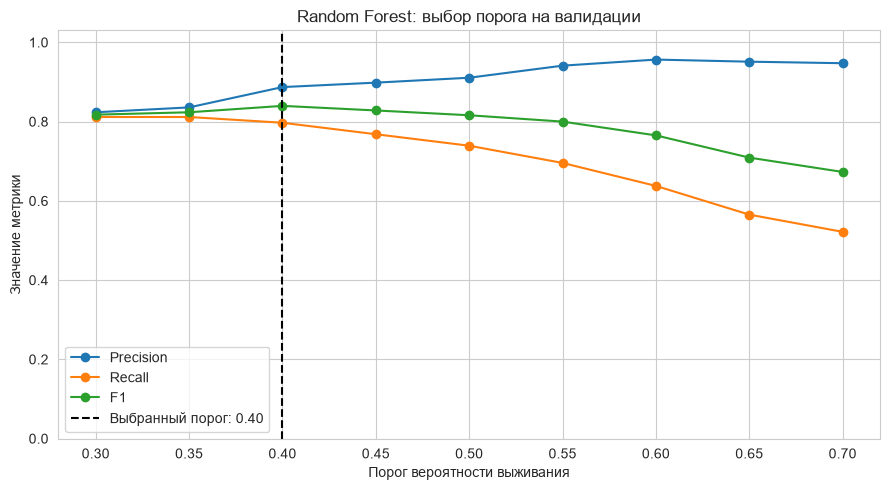

,Порог,Accuracy,Precision,Recall,F1
0,0.30,0.8603,0.8235,0.8116,0.8175
1,0.35,0.8659,0.8358,0.8116,0.8235
2,0.40,0.8827,0.8871,0.7971,0.8397
3,0.45,0.8771,0.8983,0.7681,0.8281
4,0.50,0.8715,0.9107,0.7391,0.8160
5,0.55,0.8659,0.9412,0.6957,0.8000
6,0.60,0.8492,0.9565,0.6377,0.7652
7,0.65,0.8212,0.9512,0.5652,0.7091
8,0.70,0.8045,0.9474,0.5217,0.6729


In [15]:
best_threshold_table = threshold_tables[best_name]

fig, ax = plt.subplots(figsize=(9, 5))
for metric in ['Precision', 'Recall', 'F1']:
    ax.plot(best_threshold_table['Порог'], best_threshold_table[metric],
            marker='o', label=metric)
ax.axvline(best_threshold, color='black', linestyle='--',
           label=f'Выбранный порог: {best_threshold:.2f}')
ax.set(xlabel='Порог вероятности выживания', ylabel='Значение метрики',
       title=f'{best_name}: выбор порога на валидации', ylim=(0, 1.03))
ax.legend()
plt.tight_layout()
plt.show()

display(best_threshold_table.drop(columns='Расстояние до 0.5').round(4))


# Матрицы ошибок всех моделей

Построим матрицу для baseline и каждой из пяти моделей с выбранными порогами. Во всех случаях используются одни и те же 179 валидационных пассажиров. Числа на диагонали — верные ответы; верхняя правая клетка — FP, нижняя левая — FN.


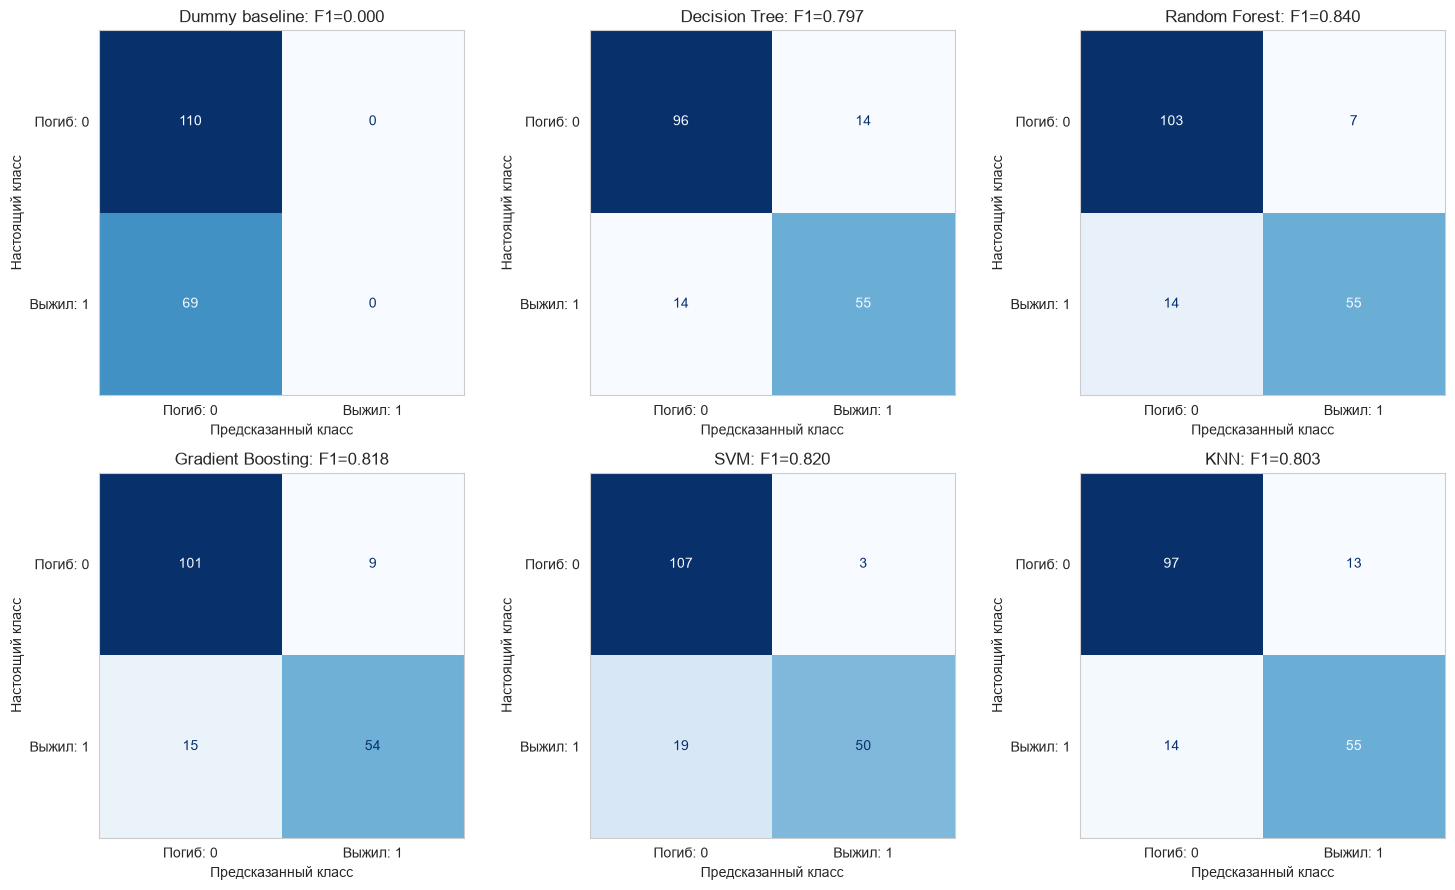

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, (name, prediction) in zip(axes.flat, validation_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_val, prediction, labels=[0, 1], display_labels=['Погиб: 0', 'Выжил: 1'],
        ax=ax, colorbar=False, cmap='Blues', values_format='d',
    )
    ax.set_title(f'{name}: F1={comparison.loc[name, "F1"]:.3f}')
    ax.set_xlabel('Предсказанный класс')
    ax.set_ylabel('Настоящий класс')
    ax.grid(False)

plt.tight_layout()
plt.show()


Random Forest: FP = 7, FN = 14; SVM: FP = 3, FN = 19; Gradient Boosting: FP = 9, FN = 15; KNN: FP = 13, FN = 14; Decision Tree: FP = 14, FN = 14.

Таким образом, одинаковые или близкие F1 могут скрывать разное соотношение ошибок. FP означает необоснованно оптимистичный прогноз для погибшего пассажира, FN — пропуск действительно выжившего. В этой учебной задаче цена ошибок отдельно не задана, поэтому выбираю решение по установленному F1.


# Важность признаков

Для дерева, леса и бустинга доступна `feature_importances_`: важность на основе уменьшения неоднородности при разбиениях. После one-hot encoding один исходный признак представлен несколькими колонками. Сложу их важности, чтобы сравнить семь исходных признаков.

Важность не показывает знак связи. Она зависит от алгоритма, параметров и обучающих данных; признаки с большим числом возможных разбиений могут получать преимущество, а связанные признаки — делить важность между собой.


,Decision Tree,Random Forest,Gradient Boosting
Sex,0.3907,0.3595,0.4891
Fare,0.2174,0.2161,0.1263
Age,0.1609,0.1796,0.1355
Pclass,0.1677,0.1278,0.1851
SibSp,0.0370,0.0443,0.0398
Embarked,0.0129,0.0382,0.0167
Parch,0.0136,0.0344,0.0076


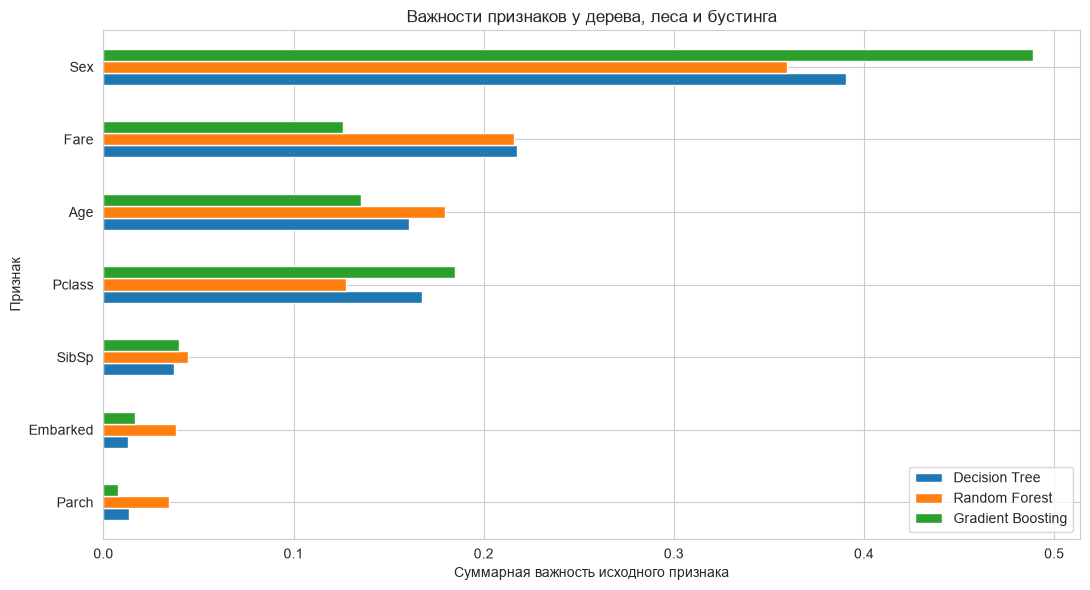

In [17]:
importance_columns = {}
for name in ['Decision Tree', 'Random Forest', 'Gradient Boosting']:
    model = models[name]
    names = model.named_steps['preprocess'].get_feature_names_out()
    # cat__Pclass_1 → Pclass; num__Age → Age.
    original_names = [name.split('__')[-1].split('_')[0] for name in names]
    importance_columns[name] = pd.Series(
        model.named_steps['classifier'].feature_importances_, index=original_names,
    ).groupby(level=0).sum()

importances = pd.DataFrame(importance_columns).sort_values('Random Forest', ascending=False)
display(importances.round(4))

importances.iloc[::-1].plot.barh(figsize=(11, 6))
plt.xlabel('Суммарная важность исходного признака')
plt.ylabel('Признак')
plt.title('Важности признаков у дерева, леса и бустинга')
plt.tight_layout()
plt.show()


Первые три признака у каждой модели:

* Decision Tree: Sex (0.391), Fare (0.217), Pclass (0.168).
* Random Forest: Sex (0.359), Fare (0.216), Age (0.180).
* Gradient Boosting: Sex (0.489), Pclass (0.185), Age (0.136).

У всех трёх моделей на первом месте Sex. У дерева и бустинга в первой тройке также Pclass, а у леса — Fare и Age. Выделение пола и класса согласуется с различиями долей выживших в первичном анализе. Лес сильнее распределяет важность между числовыми признаками. Порядок и веса различаются: одномерная доля выживших в EDA и полезность признака в совместной модели измеряют разные вещи.


Высокая важность не означает причинность. Например, важность класса билета не доказывает, что изменение значения `Pclass` в таблице изменило бы судьбу пассажира. Класс может быть связан с расположением кают, доступом к палубам и другими неучтёнными обстоятельствами. Мы анализируем предсказательные связи в наблюдаемых данных.


# Анализ ошибок выбранной модели

Теперь подробнее рассмотрим модель, выбранную по валидационному F1. Анализ ошибок будет описательным: после него не меняю признаки, настройки и порог по тем же валидационным ответам.

Сравним абсолютные количества FP и FN, а также доли ошибок внутри настоящих классов. Это разные показатели: валидация содержит больше погибших, чем выживших.


In [18]:
best_prediction = validation_predictions[best_name]
best_probability = validation_probabilities[best_name]
tn, fp, fn, tp = confusion_matrix(y_val, best_prediction, labels=[0, 1]).ravel()
print(f'TN={tn}, FP={fp}, FN={fn}, TP={tp}')
print(f'Доля FP среди погибших: {fp / (tn + fp):.3f}')
print(f'Доля FN среди выживших: {fn / (tp + fn):.3f}')

errors = X_val.copy()
errors['Id'] = df.loc[X_val.index, 'Id']
errors['Survived'] = y_val
errors['probability'] = best_probability
errors['prediction'] = best_prediction
errors['is_error'] = errors['prediction'] != errors['Survived']
errors['FP'] = (errors['Survived'] == 0) & (errors['prediction'] == 1)
errors['FN'] = (errors['Survived'] == 1) & (errors['prediction'] == 0)
errors['Age_group'] = pd.cut(
    errors['Age'], bins=[-np.inf, 12, 18, 40, 60, np.inf],
    labels=['≤12', '(12, 18]', '(18, 40]', '(40, 60]', '>60'],
).cat.add_categories(['Возраст неизвестен']).fillna('Возраст неизвестен')


TN=103, FP=7, FN=14, TP=55
Доля FP среди погибших: 0.064
Доля FN среди выживших: 0.203


Общее число ошибок выбранной модели — 21 из 179: FP = 7, FN = 14; в абсолютном количестве чаще встречаются FN. Среди действительно погибших неверный прогноз получили 6.4%, среди выживших — 20.3%. Нормировка по настоящему классу позволяет сравнивать эти доли с учётом разного числа погибших и выживших.


Проверим, для каких групп пассажиров модель ошибается чаще. Покажу и количество ошибок, и их долю: большая группа может иметь больше ошибок просто из-за размера. По малочисленным группам нельзя делать устойчивые выводы.


,count,errors,error_rate,FP,FN
Sex,,,,,
female,59,8,0.136,4,4
male,120,13,0.108,3,10


,count,errors,error_rate,FP,FN
Pclass,,,,,
1,32,3,0.094,3,0
2,43,2,0.047,1,1
3,104,16,0.154,3,13


,count,errors,error_rate,FP,FN
Age_group,,,,,
≤12,11,1,0.091,0,1
"(12, 18]",13,6,0.462,1,5
"(18, 40]",88,9,0.102,2,7
"(40, 60]",31,4,0.129,4,0
>60,4,0,0.000,0,0
Возраст неизвестен,32,1,0.031,0,1


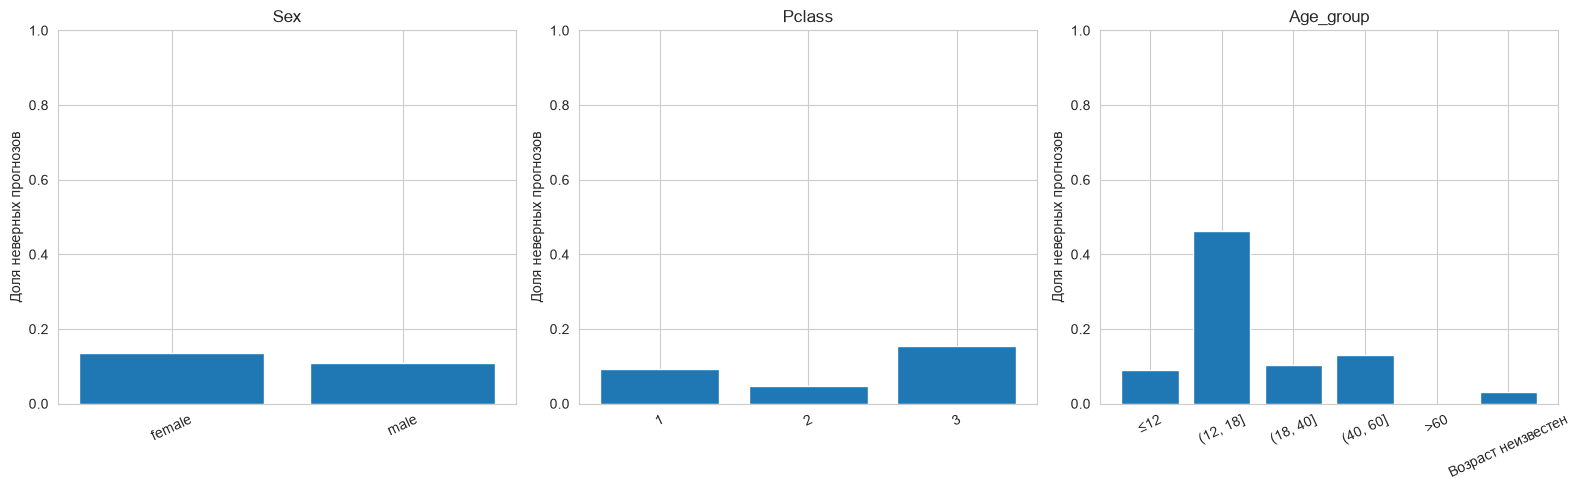

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, feature in zip(axes, ['Sex', 'Pclass', 'Age_group']):
    stats = errors.groupby(feature, observed=True).agg(
        count=('is_error', 'size'), errors=('is_error', 'sum'),
        error_rate=('is_error', 'mean'), FP=('FP', 'sum'), FN=('FN', 'sum'),
    )
    display(stats.round(3))
    ax.bar(stats.index.astype(str), stats['error_rate'])
    ax.set(title=feature, ylabel='Доля неверных прогнозов', ylim=(0, 1))
    ax.tick_params(axis='x', labelrotation=25)

plt.tight_layout()
plt.show()


По Sex наибольшая доля ошибок среди групп с n ≥ 10 наблюдается для «female»: 13.6% (8 из 59).

По Pclass наибольшая доля ошибок среди групп с n ≥ 10 наблюдается для «3»: 15.4% (16 из 104).

По Age_group наибольшая доля ошибок среди групп с n ≥ 10 наблюдается для «(12, 18]»: 46.2% (6 из 13).

Это описание данного разбиения. В малых группах один дополнительный промах сильно меняет долю, поэтому различия нельзя автоматически обобщать на всех пассажиров.


Посмотрим на несколько конкретных ошибочных прогнозов. Выберу до трёх FP и до трёх FN с наибольшей уверенностью в предсказанном классе. Это помогает увидеть разные виды ошибок, но не является репрезентативной выборкой всех пассажиров.

Для контекста добавлю долю выживших в обучающей группе с теми же полом и классом билета.

In [20]:
wrong = errors.loc[errors['is_error']].copy()
wrong['Тип ошибки'] = np.where(wrong['FP'], 'FP', 'FN')
wrong['Уверенность'] = np.where(
    wrong['prediction'] == 1, wrong['probability'], 1 - wrong['probability'],
)

error_examples = pd.concat([
    wrong.loc[wrong['FP']].nlargest(3, 'Уверенность'),
    wrong.loc[wrong['FN']].nlargest(3, 'Уверенность'),
])

training_groups = train_data.groupby(['Sex', 'Pclass']).agg(
    train_group_count=('Survived', 'size'),
    train_group_survival_rate=('Survived', 'mean'),
)
error_examples = error_examples.join(training_groups, on=['Sex', 'Pclass'])
example_columns = [
    'Id', 'Тип ошибки', 'Sex', 'Pclass', 'Age', 'SibSp', 'Parch',
    'Fare', 'Embarked', 'Survived', 'probability', 'prediction',
    'train_group_count', 'train_group_survival_rate',
]
display(error_examples[example_columns].round(4))


,Id,Тип ошибки,Sex,Pclass,Age,SibSp,Parch,Fare,Embarked,Survived,probability,prediction,train_group_count,train_group_survival_rate
881,10000257,FP,female,2,57.0,0,0,10.5000,S,0,0.8663,1,61,0.9180
438,38553373,FP,female,3,26.0,1,0,16.1000,S,0,0.7549,1,116,0.4741
563,65249351,FP,female,3,18.0,0,0,7.7750,S,0,0.5769,1,116,0.4741
310,42383068,FN,male,3,NaN,0,0,8.1125,S,1,0.0236,0,271,0.1292
870,10000246,FN,male,3,20.0,1,0,7.9250,S,1,0.0316,0,271,0.1292
739,10000115,FN,male,3,25.0,1,0,7.7750,S,1,0.0319,0,271,0.1292


* Id 10000257: женщина, класс 2, возраст 57. Факт — 0, прогноз — 1, вероятность выживания 0.866, тип ошибки — FP. В обучающей группе с теми же полом и классом выжили 91.8%; размер группы — 61. Прогноз согласуется с более частым исходом в этой группе; перенос групповой тенденции на отдельного пассажира мог способствовать ошибке.
* Id 38553373: женщина, класс 3, возраст 26. Факт — 0, прогноз — 1, вероятность выживания 0.755, тип ошибки — FP. В обучающей группе с теми же полом и классом выжили 47.4%; размер группы — 116. Частый исход этой группы отличается от прогноза: решение нужно связывать с сочетанием возраста, стоимости проезда и семейных признаков, а не только с полом и классом.
* Id 65249351: женщина, класс 3, возраст 18. Факт — 0, прогноз — 1, вероятность выживания 0.577, тип ошибки — FP. В обучающей группе с теми же полом и классом выжили 47.4%; размер группы — 116. Частый исход этой группы отличается от прогноза: решение нужно связывать с сочетанием возраста, стоимости проезда и семейных признаков, а не только с полом и классом.
* Id 42383068: мужчина, класс 3, возраст неизвестен. Факт — 1, прогноз — 0, вероятность выживания 0.024, тип ошибки — FN. В обучающей группе с теми же полом и классом выжили 12.9%; размер группы — 271. Прогноз согласуется с более частым исходом в этой группе; перенос групповой тенденции на отдельного пассажира мог способствовать ошибке.
* Id 10000246: мужчина, класс 3, возраст 20. Факт — 1, прогноз — 0, вероятность выживания 0.032, тип ошибки — FN. В обучающей группе с теми же полом и классом выжили 12.9%; размер группы — 271. Прогноз согласуется с более частым исходом в этой группе; перенос групповой тенденции на отдельного пассажира мог способствовать ошибке.
* Id 10000115: мужчина, класс 3, возраст 25. Факт — 1, прогноз — 0, вероятность выживания 0.032, тип ошибки — FN. В обучающей группе с теми же полом и классом выжили 12.9%; размер группы — 271. Прогноз согласуется с более частым исходом в этой группе; перенос групповой тенденции на отдельного пассажира мог способствовать ошибке.

Модель переносит общие закономерности на отдельного человека, но одинаковые характеристики не определяют исход однозначно. В доступных признаках нет точного местоположения пассажира, доступа к шлюпке и обстоятельств эвакуации. Это возможные источники необъяснённой вариативности, а не установленные причины конкретных ошибок. Высокая уверенность модели не гарантирует правильного ответа.


# Проверка корректности эксперимента

Вход модели состоит только из семи разрешённых характеристик. `Id` и ответ `Survived` не используются в признаках. Поля `Name`, `Ticket`, `Cabin` и исходный `PassengerId` отсутствуют.

Заполнение пропусков, кодирование и масштабирование обучались внутри pipeline только на train. Все кандидаты использовали одно разбиение. Настройки и пороги выбирались по валидации; ответы внешнего теста недоступны, публичный рейтинг не использовался.

Ограничения оценки: валидация небольшая и многократно использована для выбора решения, поэтому лучший найденный F1 может быть оптимистичным. Совпадающие профили и возможные связи между пассажирами также ограничивают независимость строк; технический `Id` не позволяет надёжно восстановить семьи. Отдельного нетронутого локального теста здесь нет. Прохождение порога на валидации не гарантирует прохождения на закрытых 700 объектах.


# Финальное обучение и посылка

Модель, гиперпараметры и порог уже выбраны. Теперь можно заново обучить выбранный pipeline на всех 891 размеченных строках: валидационные ответы больше не используются для изменения решения. Для этого создаю `clone`, чтобы сохранить прежнюю модель и её валидационные результаты.

Финальные преобразования также обучатся заново на всех размеченных данных. Внешний тест только преобразуется; ни медианы, ни категории, ни scaler по нему не вычисляются. Ранее выбранный порог оставляю прежним.


In [21]:
final_model = clone(best_model)
final_model.fit(X, y)

test = pd.read_csv(data_dir / 'test.csv')
probability = final_model.predict_proba(test[feature_columns])[:, 1]
submission = pd.DataFrame({
    'Id': test['Id'],
    'Survived': (probability >= best_threshold).astype(int),
})

sample_path = data_dir / 'sample_submission.csv'
if sample_path.exists():
    sample = pd.read_csv(sample_path)
    submission = submission.set_index('Id').loc[sample['Id']].reset_index()

assert submission.shape == (1000, 2)
assert submission['Id'].is_unique and set(submission['Id']) == set(test['Id'])
assert submission['Survived'].isin([0, 1]).all()

submission.to_csv(data_dir / 'submission.csv', index=False)
display(submission.head())
print('Распределение прогнозов:', submission['Survived'].value_counts().to_dict())


,Id,Survived
0,55586928,0
1,24554381,0
2,50120493,1
3,16342593,0
4,10829305,0


Распределение прогнозов: {0: 607, 1: 393}


На выбранном разбиении лучший результат показал Random Forest: Accuracy = 0.8827, Precision = 0.8871, Recall = 0.7971, F1 = 0.8397.